# E1: ¿cómo se mide la respiración desde el ECG (EDR)?

**Pregunta.** Hay varias formas de medir cómo la respiración modula cada latido. ¿Cuál reproduce mejor la respiración real?

**Diseño (fijado antes de correr).**
- **Variantes (8):** 4 métodos × 2 preprocesamientos.
  - Métodos: amplitud del pico dominante (con refinamiento parabólico), pico a pico del QRS, área del QRS y primera componente principal (PCA) de los latidos.
  - Preprocesamientos: pasabanda Butterworth 0,5–40 Hz de fase cero, o señal cruda restando a cada latido la mediana del segmento PR (−100 a −50 ms).
- **Fijo para todas:** centro y polaridad del QRS medidos en cada registro (`qrs_reference`); latidos con RR entre 0,3 y 2 s; ventana de ±60 ms; remuestreo cúbico a 2 Hz.
- **Datos:** los 8 registros con respiración real (8 sujetos, todos en desarrollo).
- **Métrica:** coherencia entre el EDR y la respiración, ponderada por el espectro de la respiración (≥ 0,05 Hz), en ventanas de 2 min; mediana por registro; promedio de los 3 canales (tórax, abdomen, flujo nasal).
- **Incertidumbre:** bootstrap sobre los 8 registros (5.000 remuestreos): intervalo del 95 % de cada variante, de la diferencia con la mejor, y probabilidad de ser la mejor.
- **Regla:** gana la de mayor media. Si otras no se distinguen de ella (el intervalo de la diferencia incluye 0), se elige entre las empatadas la más simple, en este orden: primero el método (amplitud < pico a pico < área < PCA), después el preprocesamiento (pasabanda < cruda).
- **Chequeo:** se repite con interpolación lineal para ver si cambia el ranking.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RESP_RECORDS, RESULTS_DIR, SPLIT_CSV
from src.data import load_ecg, load_qrs, load_respiration
from src.features.coupling import downsample, resample_uniform
from src.features.edr import (beat_matrix, edr_amplitude, edr_area, edr_pca, edr_peak_to_peak,
                              edr_series, qrs_reference, validate_edr)
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.qrs.rr_clean import rr_in_range

FIG = RESULTS_DIR / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"

split = pd.read_csv(SPLIT_CSV).set_index("record")
assert (split.loc[RESP_RECORDS, "set"] == "dev").all()     # solo desarrollo

METODOS = ["amplitud", "pico a pico", "área", "PCA"]
PREPROS = ["pasabanda", "cruda"]
CANALES = ["Resp C", "Resp A", "Resp N"]
FS_U = 2.0

In [2]:
def edr_por_metodo(x, qrs, fs, baseline):
    off, sign = qrs_reference(x, qrs, fs)
    centers = qrs + off
    valid = rr_in_range(centers / fs)
    beats, ok = beat_matrix(x, centers, fs, 0.06, baseline)
    t, valid = centers[ok] / fs, valid[ok]
    valores = {"amplitud": edr_amplitude(beats, sign), "pico a pico": edr_peak_to_peak(beats),
               "área": edr_area(beats, sign, fs), "PCA": edr_pca(beats)}
    return sign, {m: edr_series(t, v, valid) for m, v in valores.items()}

filas, info, series_pb, resps = [], [], {}, {}
for rec in RESP_RECORDS:
    ecg, fs = load_ecg(rec)
    qrs = load_qrs(rec)
    resp, fs_r = load_respiration(rec)
    resp2 = {c: downsample(resp[c], fs_r, FS_U) for c in CANALES}
    for pre in PREPROS:
        if pre == "pasabanda":
            x, base = apply_zero_phase(ecg, design_bandpass(fs, 0.5, 40, 2)), None
        else:
            x, base = ecg, (-0.10, -0.05)
        sign, series = edr_por_metodo(x, qrs, fs, base)
        if pre == "pasabanda":
            info.append({"registro": rec, "polaridad": sign, "latidos válidos": len(series["amplitud"][0])})
        for met, (t, v) in series.items():
            for kind in ("cubic", "linear"):
                tu, vu = resample_uniform(t, v, FS_U, kind)
                idx = np.rint(tu * FS_U).astype(int)
                for c in CANALES:
                    sel = idx < len(resp2[c])
                    w = validate_edr(vu[sel], resp2[c][idx[sel]], FS_U)
                    filas.append({"registro": rec, "pre": pre, "método": met, "interp": kind,
                                  "canal": c, "coherencia": np.nanmedian(w),
                                  "ventanas": len(w), "descartadas": int(np.isnan(w).sum())})
                if kind == "cubic" and pre == "pasabanda":
                    series_pb[(rec, met)] = (tu, vu)
    resps[rec] = resp2
ejemplos = {met: series_pb[("a03", met)] for met in METODOS}
ejemplo_resp = resps["a03"]

res = pd.DataFrame(filas)
# La respiración tiene muestras inválidas (NaN): las ventanas que las tocan se descartan.
desc = (res[(res.interp == "cubic") & (res.método == "amplitud") & (res.pre == "pasabanda")]
        .pivot(index="registro", columns="canal", values="descartadas"))
info = pd.DataFrame(info).set_index("registro")
info["ventanas de 2 min"] = res.groupby("registro").ventanas.max()
for c in CANALES:
    info[f"descartadas {c}"] = desc[c]
info

,polaridad,latidos válidos,ventanas de 2 min,descartadas Resp C,descartadas Resp A,descartadas Resp N
registro,,,,,,
a01,1,29936,246,4,171,0
a02,1,32123,265,10,163,0
a03,1,34245,261,24,7,0
a04,1,31204,248,30,43,1
b01,1,35071,243,15,28,0
c01,1,27735,241,1,21,0
c02,-1,32162,248,4,4,0
c03,1,23760,226,7,25,0


## Un ejemplo: 2 minutos de a03

La respiración real (tórax) contra los cuatro EDR, todos estandarizados para poder superponerlos.

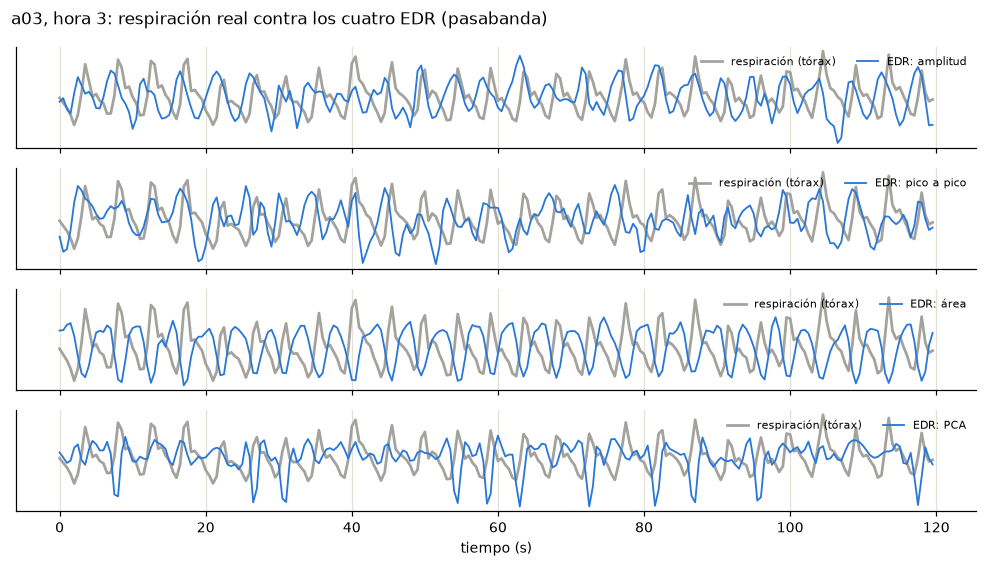

In [3]:
t0 = 3 * 3600                                    # hora 3 de la noche
fig, axes = plt.subplots(4, 1, figsize=(9, 5.2), sharex=True)
r = ejemplo_resp["Resp C"]
tr = np.arange(len(r)) / FS_U
m = (tr >= t0) & (tr < t0 + 120)
z = lambda s: (s - s.mean()) / s.std()
for ax, met in zip(axes, METODOS):
    tu, vu = ejemplos[met]
    me = (tu >= t0) & (tu < t0 + 120)
    ax.plot(tr[m] - t0, z(r[m]), color=GRIS, lw=1.8, label="respiración (tórax)")
    ax.plot(tu[me] - t0, z(vu[me]), color=AZUL, lw=1.2, label=f"EDR: {met}")
    ax.legend(loc="upper right", fontsize=7, frameon=False, ncol=2)
    ax.set_yticks([])
axes[-1].set_xlabel("tiempo (s)")
fig.suptitle("a03, hora 3: respiración real contra los cuatro EDR (pasabanda)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "E1_ejemplo_a03.png")

## Resultados

Coherencia mediana por registro, promediando los tres canales de respiración (interpolación cúbica).

In [4]:
VARIANTES = [(pre, met) for met in METODOS for pre in PREPROS]      # orden de simplicidad
nombre = lambda v: f"{v[1]} ({v[0]})"
cub = res[res.interp == "cubic"]
tabla = (cub.groupby(["registro", "pre", "método"]).coherencia.mean()
            .unstack(["pre", "método"]))
tabla = tabla[[(p, m) for p, m in VARIANTES]]
tabla.columns = [nombre(v) for v in VARIANTES]
tabla.round(3)

,amplitud (pasabanda),amplitud (cruda),pico a pico (pasabanda),pico a pico (cruda),área (pasabanda),área (cruda),PCA (pasabanda),PCA (cruda)
registro,,,,,,,,
a01,0.494,0.467,0.565,0.524,0.515,0.427,0.190,0.189
a02,0.301,0.253,0.295,0.277,0.348,0.343,0.295,0.278
a03,0.468,0.341,0.371,0.323,0.456,0.400,0.191,0.191
a04,0.252,0.236,0.242,0.224,0.315,0.351,0.177,0.179
b01,0.346,0.289,0.332,0.254,0.620,0.654,0.161,0.162
c01,0.298,0.213,0.578,0.383,0.703,0.477,0.164,0.229
c02,0.372,0.366,0.344,0.409,0.531,0.516,0.187,0.188
c03,0.466,0.331,0.564,0.355,0.759,0.682,0.164,0.167


In [5]:
def comparar(tabla, n_boot=5000, seed=2026):
    # Bootstrap sobre registros: media de cada variante, IC 95 %, P(mejor) y diferencia con la mejor.
    rng = np.random.default_rng(seed)
    X = tabla.to_numpy()
    idx = rng.integers(0, len(X), size=(n_boot, len(X)))
    medias = X[idx].mean(axis=1)                                 # n_boot x variantes
    media = X.mean(axis=0)
    mejor = int(np.argmax(media))
    dif = medias - medias[:, [mejor]]
    out = pd.DataFrame({
        "media": media,
        "IC 95 %": [f"{a:.3f} a {b:.3f}" for a, b in np.percentile(medias, [2.5, 97.5], axis=0).T],
        "P(mejor)": np.bincount(medias.argmax(axis=1), minlength=X.shape[1]) / n_boot,
        "dif. con la mejor": media - media[mejor],
        "IC dif.": [f"{a:+.3f} a {b:+.3f}" for a, b in np.percentile(dif, [2.5, 97.5], axis=0).T],
        "empata con la mejor": np.percentile(dif, 97.5, axis=0) >= 0,
    }, index=tabla.columns)
    return out

resumen = comparar(tabla)
resumen.sort_values("media", ascending=False).round(3)

,media,IC 95 %,P(mejor),dif. con la mejor,IC dif.,empata con la mejor
área (pasabanda),0.531,0.434 a 0.635,0.975,0.000,+0.000 a +0.000,True
área (cruda),0.481,0.404 a 0.567,0.025,-0.050,-0.109 a -0.000,False
pico a pico (pasabanda),0.411,0.327 a 0.505,0.000,-0.120,-0.186 a -0.052,False
amplitud (pasabanda),0.375,0.315 a 0.434,0.000,-0.156,-0.258 a -0.064,False
pico a pico (cruda),0.343,0.284 a 0.411,0.000,-0.188,-0.290 a -0.093,False
amplitud (cruda),0.312,0.262 a 0.367,0.000,-0.219,-0.337 a -0.116,False
PCA (cruda),0.198,0.177 a 0.226,0.000,-0.333,-0.447 a -0.222,False
PCA (pasabanda),0.191,0.170 a 0.223,0.000,-0.340,-0.461 a -0.219,False


In [6]:
def decidir(resumen):
    # La de mayor media; si hay empates, la primera en el orden de simplicidad (orden de las columnas).
    empatadas = [v for v in resumen.index if resumen.loc[v, "empata con la mejor"]]
    return resumen["media"].idxmax(), empatadas[0], empatadas

mejor, elegida, empatadas = decidir(resumen)
print(f"mayor media: {mejor}")
print(f"no se distinguen de ella: {', '.join(empatadas)}")
print(f"ELEGIDA (la más simple entre las empatadas): {elegida}")

mayor media: área (pasabanda)
no se distinguen de ella: área (pasabanda)
ELEGIDA (la más simple entre las empatadas): área (pasabanda)


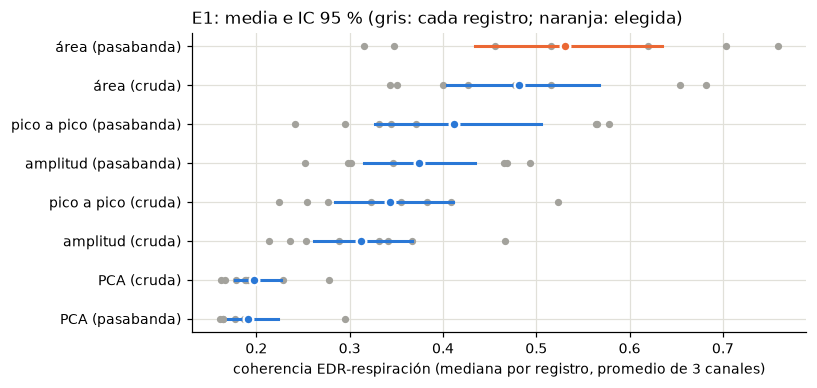

In [7]:
orden = resumen.sort_values("media").index
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, v in enumerate(orden):
    ax.scatter(tabla[v], np.full(len(tabla), i), s=14, color=GRIS, zorder=2)
    lo, hi = map(float, resumen.loc[v, "IC 95 %"].split(" a "))
    color = NARANJA if v == elegida else AZUL
    ax.plot([lo, hi], [i, i], color=color, lw=2, zorder=3)
    ax.scatter(resumen.loc[v, "media"], i, s=40, color=color, edgecolor="white", linewidth=1.5, zorder=4)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlabel("coherencia EDR-respiración (mediana por registro, promedio de 3 canales)")
ax.set_title("E1: media e IC 95 % (gris: cada registro; naranja: elegida)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "E1_comparacion.png")

### ¿Cuánto da el azar?

Para saber si una coherencia es alta hace falta compararla con la que da un EDR que **no** tiene relación con esa respiración. Se desplaza cada EDR 10 minutos respecto de la respiración (de forma circular) y se repite la medición: lo que queda es el piso de ruido de la métrica.

In [8]:
filas_nulo = []
for (rec, met), (tu, vu) in series_pb.items():
    idx = np.rint(tu * FS_U).astype(int)
    for c in CANALES:
        sel = idx < len(resps[rec][c])
        nulo = validate_edr(np.roll(vu[sel], int(600 * FS_U)), resps[rec][c][idx[sel]], FS_U)
        filas_nulo.append({"registro": rec, "método": met, "canal": c, "nulo": np.nanmedian(nulo)})
nulo = pd.DataFrame(filas_nulo).groupby(["método", "registro"]).nulo.mean().groupby("método").agg(["mean", "max"])
real = cub[cub.pre == "pasabanda"].groupby(["método", "registro"]).coherencia.mean().groupby("método").mean()
comp = pd.DataFrame({"coherencia real (media)": real, "azar: media": nulo["mean"], "azar: máximo por registro": nulo["max"]})
comp.loc[METODOS].round(3)

,coherencia real (media),azar: media,azar: máximo por registro
método,,,
amplitud,0.375,0.162,0.171
pico a pico,0.411,0.166,0.178
área,0.531,0.164,0.173
PCA,0.191,0.161,0.170


### Por canal de respiración

La misma comparación contra cada canal por separado: ¿el resultado depende de qué respiración se tome como verdad?

In [9]:
por_canal = {}
for c in CANALES:
    tc = (cub[cub.canal == c].groupby(["registro", "pre", "método"]).coherencia.mean()
              .unstack(["pre", "método"]))[[(p, m) for p, m in VARIANTES]]
    tc.columns = tabla.columns
    rc = comparar(tc)
    por_canal[c] = rc["media"].round(3).astype(str) + "  (P=" + rc["P(mejor)"].round(2).astype(str) + ")"
    print(f"{c}: mayor media = {rc['media'].idxmax()}, elegida por la regla = {decidir(rc)[1]}")
pd.DataFrame(por_canal)

Resp C: mayor media = área (pasabanda), elegida por la regla = área (pasabanda)
Resp A: mayor media = área (pasabanda), elegida por la regla = área (pasabanda)
Resp N: mayor media = área (pasabanda), elegida por la regla = área (pasabanda)


,Resp C,Resp A,Resp N
amplitud (pasabanda),0.373 (P=0.0),0.372 (P=0.0),0.378 (P=0.0)
amplitud (cruda),0.314 (P=0.0),0.316 (P=0.0),0.307 (P=0.0)
pico a pico (pasabanda),0.408 (P=0.0),0.409 (P=0.0),0.417 (P=0.0)
pico a pico (cruda),0.343 (P=0.0),0.341 (P=0.0),0.346 (P=0.0)
área (pasabanda),0.53 (P=0.99),0.535 (P=0.95),0.528 (P=0.97)
área (cruda),0.477 (P=0.01),0.49 (P=0.05),0.477 (P=0.03)
PCA (pasabanda),0.186 (P=0.0),0.196 (P=0.0),0.191 (P=0.0)
PCA (cruda),0.192 (P=0.0),0.202 (P=0.0),0.199 (P=0.0)


### Chequeo: interpolación lineal en vez de cúbica

In [10]:
lin = res[res.interp == "linear"]
tl = (lin.groupby(["registro", "pre", "método"]).coherencia.mean().unstack(["pre", "método"]))[[(p, m) for p, m in VARIANTES]]
tl.columns = tabla.columns
rl = comparar(tl)
rank = pd.DataFrame({"cúbica": resumen["media"].rank(ascending=False).astype(int),
                     "lineal": rl["media"].rank(ascending=False).astype(int)})
print(f"elegida con lineal: {decidir(rl)[1]} | correlación de rankings (Spearman): "
      f"{rank.corr(method='spearman').iloc[0, 1]:.2f}")
rank.sort_values("cúbica")

elegida con lineal: área (pasabanda) | correlación de rankings (Spearman): 1.00


,cúbica,lineal
área (pasabanda),1,1
área (cruda),2,2
pico a pico (pasabanda),3,3
amplitud (pasabanda),4,4
pico a pico (cruda),5,5
amplitud (cruda),6,6
PCA (cruda),7,7
PCA (pasabanda),8,8


## Decisión

- **Elegido: área del QRS sobre el ECG con pasabanda.** Tiene la mayor coherencia media con la respiración real (0,53; IC 95 % 0,43 a 0,64) y es la mejor en el 97,5 % de los remuestreos. Ninguna otra variante empata con ella: la segunda, el área sin pasabanda, queda 0,05 abajo (IC de la diferencia −0,11 a −0,00).
- **El resultado es estable.** Gana contra los tres canales de respiración (tórax, abdomen y flujo nasal), y el ranking de las 8 variantes es idéntico con interpolación cúbica o lineal.
- **Está muy por encima del azar.** Con el EDR desalineado 10 minutos la coherencia cae a 0,16. El área triplica ese piso; la amplitud y el pico a pico lo duplican.
- **PCA casi no capta la respiración:** 0,19 contra 0,16 del azar. La primera componente es la dirección de mayor variación de los latidos; que no siga a la respiración indica que la mayor variación de la forma del QRS viene de otra cosa. No se investigó de qué.
- **El pasabanda mejora a los tres métodos que funcionan** (área 0,53 contra 0,48; pico a pico 0,41 contra 0,34; amplitud 0,38 contra 0,31).
- **Límites.** Son 8 registros de 8 sujetos. Una coherencia de 0,53 indica que el EDR sigue a la respiración pero no la reproduce exactamente. La comparación usa toda la noche, sin separar minutos con y sin apnea. El pasabanda (0,5–40 Hz, orden 2) es el común a este experimento: si la etapa 4.2 elige otro filtro, E1 se repite con ese.

**Cambio en el pipeline:** el EDR se calcula como el área con signo del QRS (±60 ms alrededor del centro del QRS, con la polaridad medida en cada registro) sobre el ECG con pasabanda. Reemplaza a la amplitud R del esquema v2.